<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/notebooks/04_emendas_convenios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise de Transferências Voluntárias: Emendas Parlamentares e Convênios (RN 2020–2023)
**Projeto da 2ª Unidade — Ciência de Dados (IMD/UFRN)**  
*Responsável:* Pessoa B (Brenda Gomes)  
*Objetivo:* Investigar para onde foram as **Emendas Parlamentares Federais** (Emendas PIX da EC 105/2019 e Convênios federais via SICONV/Transferegov) no quadriênio completo de **2020 a 2023**, comparando a desigualdade (Gini), a lógica distributiva (PIB e CadÚnico) e o impacto orçamentário frente aos repasses constitucionais obrigatórios.

## 1. Configuração do Ambiente e Carregamento dos Dados Consolidados (2020–2023)

Carregamos a base integrada contendo os 167 municípios do RN ao longo dos 4 anos (668 registros), devidamente corrigidos pela inflação (IPCA a preços de 2023) e enriquecidos com:
1. **Emendas PIX (Transferências Especiais):** Extraídas da API oficial do Transferegov.
2. **Emendas via Convênios (SICONV):** Dados federais abertos de instrumentos pactuados.
3. **Repasses Obrigatórios (ICMS, IPVA, IPI, Royalties):** Dados oficiais da SEFAZ-RN.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import os
import requests
from concurrent.futures import ThreadPoolExecutor

# Estilo visual padronizado
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "figure.titlesize": 14,
    "figure.titleweight": "bold"
})

# Caminhos locais e URL remota de fallback
caminho_base = os.path.join("..", "saida", "base_com_emendas_2020_2023.csv")
caminho_local_direto = os.path.join("saida", "base_com_emendas_2020_2023.csv")
url_github = "https://raw.githubusercontent.com/Renata-Nascimento/Projeto-U02-CD/main/saida/base_com_emendas_2020_2023.csv"

if os.path.exists(caminho_base):
    df = pd.read_csv(caminho_base)
    print(f"Base carregada via caminho relativo ({caminho_base}): {df.shape}")
elif os.path.exists(caminho_local_direto):
    df = pd.read_csv(caminho_local_direto)
    print(f"Base carregada via caminho direto ({caminho_local_direto}): {df.shape}")
else:
    print("Baixando base diretamente do GitHub...")
    df = pd.read_csv(url_github)
    print(f"Base baixada com sucesso: {df.shape}")

# Criação do DataFrame Acumulado Quadrienal (2020-2023) corrigido pelo IPCA
df_acumulado = df.groupby(["cod_ibge", "municipio", "mesorregiao", "porte"]).agg(
    populacao_media=("populacao", "mean"),
    pct_baixa_renda_media=("pct_baixa_renda", "mean"),
    pib_pc_medio=("pib_per_capita", "mean"),
    rep_total_real_acumulado=("rep_total_real", "sum"),
    emendas_pix_real_acumulado=("emendas_pix", lambda x: (x * df.loc[x.index, "fator_ipca"]).sum()),
    emendas_convenio_real_acumulado=("emendas_convenio", lambda x: (x * df.loc[x.index, "fator_ipca"]).sum()),
    emendas_total_real_acumulado=("emendas_total_real", "sum")
).reset_index()

df_acumulado["rep_pc_acumulado"] = df_acumulado["rep_total_real_acumulado"] / df_acumulado["populacao_media"]
df_acumulado["emendas_pc_acumulado"] = df_acumulado["emendas_total_real_acumulado"] / df_acumulado["populacao_media"]
df_acumulado["total_pc_acumulado"] = (df_acumulado["rep_total_real_acumulado"] + df_acumulado["emendas_total_real_acumulado"]) / df_acumulado["populacao_media"]

print(f"Total de municípios no acumulado 2020-2023: {len(df_acumulado)}")
display(df_acumulado.head(3))

Base carregada via caminho direto (saida\base_com_emendas_2020_2023.csv): (668, 28)
Total de municípios no acumulado 2020-2023: 167


,cod_ibge,municipio,mesorregiao,porte,populacao_media,pct_baixa_renda_media,pib_pc_medio,rep_total_real_acumulado,emendas_pix_real_acumulado,emendas_convenio_real_acumulado,emendas_total_real_acumulado,rep_pc_acumulado,emendas_pc_acumulado,total_pc_acumulado
0,2400109,Acari,Central Potiguar,10–20 mil,10597.0,53.333491,16596.989634,1.950637e+07,1.419301e+07,2.863888e+07,4.283189e+07,1840.744402,4041.888004,5882.632406
1,2400208,Assú,Oeste Potiguar,mais de 50 mil,56496.0,58.102786,33364.591334,1.407425e+08,2.556831e+06,0.000000e+00,2.556831e+06,2491.194349,45.256854,2536.451204
2,2400307,Afonso Bezerra,Central Potiguar,10–20 mil,10839.0,66.911154,15982.816324,1.701068e+07,4.214311e+06,1.072582e+06,5.286894e+06,1569.395242,487.765804,2057.161046


## 2. Desigualdade na Distribuição: Emendas vs. Repasses Obrigatórios (2020–2023)

Avaliamos a concentração e a desigualdade dos recursos tanto **ano a ano** quanto no **acumulado real do quadriênio 2020–2023**.

=== EVOLUÇÃO TEMPORAL DA DESIGUALDADE (GINI 2020-2023) ===


,Ano,Gini Repasses Obrigatórios,Gini Emendas Parlamentares,Gini Combinado (Repasses + Emendas),Total Emendas (R$ Milhões Reais),% Emendas PIX
0,2020,0.429,0.611,0.414,R$ 227.4M,9.7%
1,2021,0.432,0.566,0.408,R$ 217.8M,21.3%
2,2022,0.423,0.690,0.418,R$ 214.2M,28.6%
3,2023,0.425,0.654,0.409,R$ 259.0M,63.0%


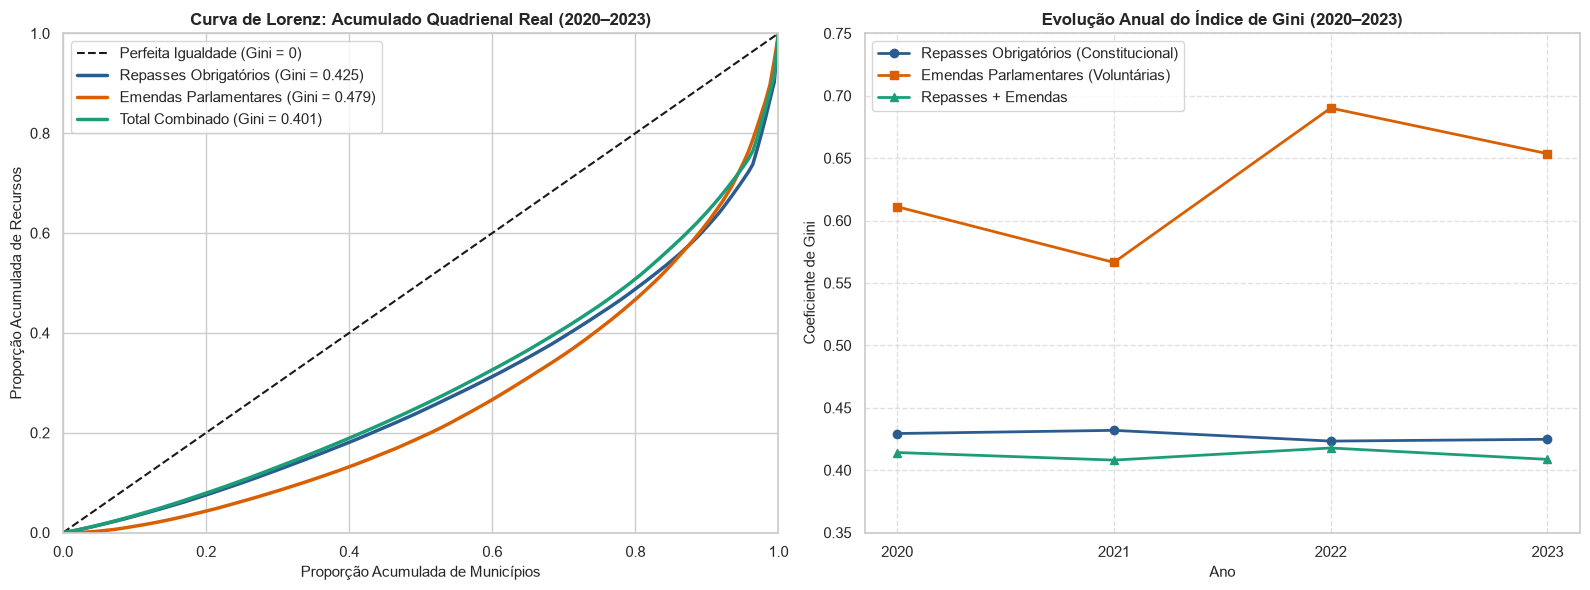

In [2]:
# Funções vetoriais para Gini e Curva de Lorenz
def calcular_gini(valores):
    arr = np.asarray(valores, dtype=float).flatten()
    arr = arr[~np.isnan(arr)]
    if np.amin(arr) < 0:
        arr -= np.amin(arr)
    arr += 1e-9
    arr = np.sort(arr)
    n = arr.shape[0]
    index = np.arange(1, n + 1)
    return (np.sum((2 * index - n - 1) * arr)) / (n * np.sum(arr))

def curva_lorenz(valores):
    arr = np.sort(np.asarray(valores, dtype=float))
    cum_vals = np.cumsum(arr)
    cum_vals = np.insert(cum_vals, 0, 0)
    cum_pct = cum_vals / cum_vals[-1]
    pop_pct = np.linspace(0, 1, len(cum_pct))
    return pop_pct, cum_pct

# 1. Tabela de Gini ano a ano (2020 a 2023)
anos = [2020, 2021, 2022, 2023]
tabela_gini = []
for ano in anos:
    df_ano = df[df["ano"] == ano]
    tabela_gini.append({
        "Ano": ano,
        "Gini Repasses Obrigatórios": calcular_gini(df_ano["rep_per_capita"]),
        "Gini Emendas Parlamentares": calcular_gini(df_ano["emendas_per_capita"]),
        "Gini Combinado (Repasses + Emendas)": calcular_gini(df_ano["cenario_2_repasses_mais_emendas_pc"]),
        "Total Emendas (R$ Milhões Reais)": df_ano["emendas_total_real"].sum() / 1e6,
        "% Emendas PIX": (df_ano["emendas_pix"].sum() / df_ano["emendas_total"].sum()) * 100
    })

df_gini_anos = pd.DataFrame(tabela_gini)
print("=== EVOLUÇÃO TEMPORAL DA DESIGUALDADE (GINI 2020-2023) ===")
display(df_gini_anos.style.format({
    "Gini Repasses Obrigatórios": "{:.3f}",
    "Gini Emendas Parlamentares": "{:.3f}",
    "Gini Combinado (Repasses + Emendas)": "{:.3f}",
    "Total Emendas (R$ Milhões Reais)": "R$ {:.1f}M",
    "% Emendas PIX": "{:.1f}%"
}))

# 2. Curvas de Lorenz para o Acumulado Real do Quadriênio (2020-2023)
gini_rep_acum = calcular_gini(df_acumulado["rep_pc_acumulado"])
gini_eme_acum = calcular_gini(df_acumulado["emendas_pc_acumulado"])
gini_tot_acum = calcular_gini(df_acumulado["total_pc_acumulado"])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Curva de Lorenz do Acumulado
axes[0].plot([0, 1], [0, 1], "k--", label="Perfeita Igualdade (Gini = 0)")
x_rep, y_rep = curva_lorenz(df_acumulado["rep_pc_acumulado"])
axes[0].plot(x_rep, y_rep, label=f"Repasses Obrigatórios (Gini = {gini_rep_acum:.3f})", color="#2b5c8f", lw=2.5)
x_eme, y_eme = curva_lorenz(df_acumulado["emendas_pc_acumulado"])
axes[0].plot(x_eme, y_eme, label=f"Emendas Parlamentares (Gini = {gini_eme_acum:.3f})", color="#d95f02", lw=2.5)
x_tot, y_tot = curva_lorenz(df_acumulado["total_pc_acumulado"])
axes[0].plot(x_tot, y_tot, label=f"Total Combinado (Gini = {gini_tot_acum:.3f})", color="#1b9e77", lw=2.5)

axes[0].set_title("Curva de Lorenz: Acumulado Quadrienal Real (2020–2023)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Proporção Acumulada de Municípios", fontsize=11)
axes[0].set_ylabel("Proporção Acumulada de Recursos", fontsize=11)
axes[0].legend(frameon=True, loc="upper left")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)

# Subplot 2: Evolução Anual do Gini
axes[1].plot(df_gini_anos["Ano"], df_gini_anos["Gini Repasses Obrigatórios"], marker="o", lw=2, color="#2b5c8f", label="Repasses Obrigatórios (Constitucional)")
axes[1].plot(df_gini_anos["Ano"], df_gini_anos["Gini Emendas Parlamentares"], marker="s", lw=2, color="#d95f02", label="Emendas Parlamentares (Voluntárias)")
axes[1].plot(df_gini_anos["Ano"], df_gini_anos["Gini Combinado (Repasses + Emendas)"], marker="^", lw=2, color="#1b9e77", label="Repasses + Emendas")
axes[1].set_title("Evolução Anual do Índice de Gini (2020–2023)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Ano", fontsize=11)
axes[1].set_ylabel("Coeficiente de Gini", fontsize=11)
axes[1].set_xticks(anos)
axes[1].set_ylim(0.35, 0.75)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

> **Interpretação:**
> 1. **Estabilidade Constitucional vs. Volatilidade Política:** O Gini dos repasses obrigatórios é estável em torno de **0,423 a 0,432** ao longo de todos os quatro anos, refletindo a rigidez das regras da CF/88. Já o Gini das emendas é persistentemente alto (entre **0,566 e 0,690**), atingindo seu pico máximo de concentração em 2022 (ano de eleições gerais).
> 2. **Acumulado Quadrienal:** Mesmo quando somamos os 4 anos inteiros (eliminando oscilações anuais de pagamento), o Gini das emendas acumuladas permanece em **0,479**, consideravelmente superior ao dos repasses constitucionais (0,425).

## 3. Critério Distributivo: Quem Recebe as Emendas no Quadriênio 2020–2023?

Testamos se as emendas atenderam aos municípios com maior contingente de famílias de baixa renda (CadÚnico) ou se acompanharam a dinâmica econômica (PIB per capita), tanto ano a ano quanto no acumulado real de 2020 a 2023.

=== MATRIZ DE CORRELAÇÃO DE PEARSON ANO A ANO ===


,Ano,"Corr(Emendas pc, % CadÚnico)","Corr(Emendas pc, PIB pc)","Corr(Repasses pc, PIB pc)"
0,2020,-0.001,0.004,0.772
1,2021,0.205,0.048,0.740
2,2022,0.059,-0.038,0.842
3,2023,-0.042,0.087,0.811


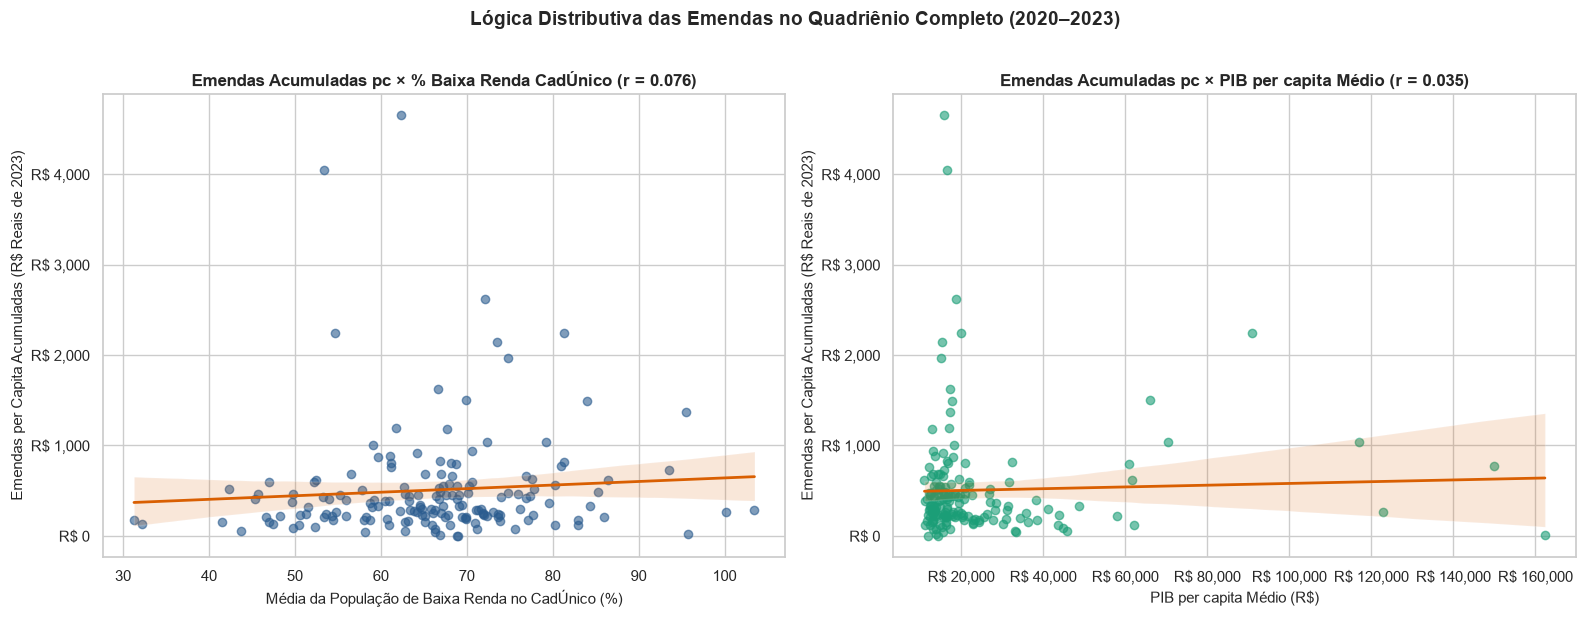

In [3]:
# Cálculo de correlações ano a ano e no acumulado
corr_anos = []
for ano in anos:
    df_ano = df[df["ano"] == ano]
    corr_anos.append({
        "Ano": ano,
        "Corr(Emendas pc, % CadÚnico)": df_ano["emendas_per_capita"].corr(df_ano["pct_baixa_renda"]),
        "Corr(Emendas pc, PIB pc)": df_ano["emendas_per_capita"].corr(df_ano["pib_per_capita"]),
        "Corr(Repasses pc, PIB pc)": df_ano["rep_per_capita"].corr(df_ano["pib_per_capita"])
    })

df_corr_anos = pd.DataFrame(corr_anos)
print("=== MATRIZ DE CORRELAÇÃO DE PEARSON ANO A ANO ===")
display(df_corr_anos.style.format("{:.3f}", subset=["Corr(Emendas pc, % CadÚnico)", "Corr(Emendas pc, PIB pc)", "Corr(Repasses pc, PIB pc)"]))

# Gráficos de dispersão no Acumulado Quadrienal 2020-2023
corr_cad_acum = df_acumulado["emendas_pc_acumulado"].corr(df_acumulado["pct_baixa_renda_media"])
corr_pib_acum = df_acumulado["emendas_pc_acumulado"].corr(df_acumulado["pib_pc_medio"])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Dispersão 1: Emendas Acumuladas x % Baixa Renda no CadÚnico
sns.regplot(data=df_acumulado, x="pct_baixa_renda_media", y="emendas_pc_acumulado",
            scatter_kws={"alpha": 0.6, "color": "#2b5c8f"}, line_kws={"color": "#d95f02", "lw": 2}, ax=axes[0])
axes[0].set_title(f"Emendas Acumuladas pc × % Baixa Renda CadÚnico (r = {corr_cad_acum:.3f})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Média da População de Baixa Renda no CadÚnico (%)", fontsize=11)
axes[0].set_ylabel("Emendas per Capita Acumuladas (R$ Reais de 2023)", fontsize=11)
axes[0].yaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))

# Dispersão 2: Emendas Acumuladas x PIB per capita
sns.regplot(data=df_acumulado, x="pib_pc_medio", y="emendas_pc_acumulado",
            scatter_kws={"alpha": 0.6, "color": "#1b9e77"}, line_kws={"color": "#d95f02", "lw": 2}, ax=axes[1])
axes[1].set_title(f"Emendas Acumuladas pc × PIB per capita Médio (r = {corr_pib_acum:.3f})", fontsize=12, fontweight="bold")
axes[1].set_xlabel("PIB per capita Médio (R$)", fontsize=11)
axes[1].set_ylabel("Emendas per Capita Acumuladas (R$ Reais de 2023)", fontsize=11)
axes[1].yaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))
axes[1].xaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))

plt.suptitle("Lógica Distributiva das Emendas no Quadriênio Completo (2020–2023)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

> **Interpretação:**
> 1. **Ausência de Critério Redistributivo Social:** A correlação entre emendas per capita e a taxa de pobreza no CadÚnico é de **+0,076 no acumulado** e oscila entre -0,042 e +0,205 nos anos individuais. Isso comprova estatisticamente que a destinação de emendas não responde à vulnerabilidade social dos municípios do RN.
> 2. **Descolamento da Atividade Econômica:** A correlação com o PIB per capita é praticamente zero (**r = +0,035 no acumulado**). Enquanto o repasse de ICMS espelha a dinâmica produtiva dos municípios, as emendas independem da capacidade econômica, confirmando o caráter discricionário e político da alocação.

## 4. A Ascensão das Emendas PIX (Transferências Especiais: 2020–2023)

Analisamos a evolução da composição dos repasses de emendas: a substituição acelerada dos convênios tradicionais pelas **Transferências Especiais (Emendas PIX)** da Emenda Constitucional 105/2019.

C:\Users\acer nitro5\AppData\Local\Temp\ipykernel_14000\4151681257.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  totais_anuais_reais = df.groupby("ano").apply(


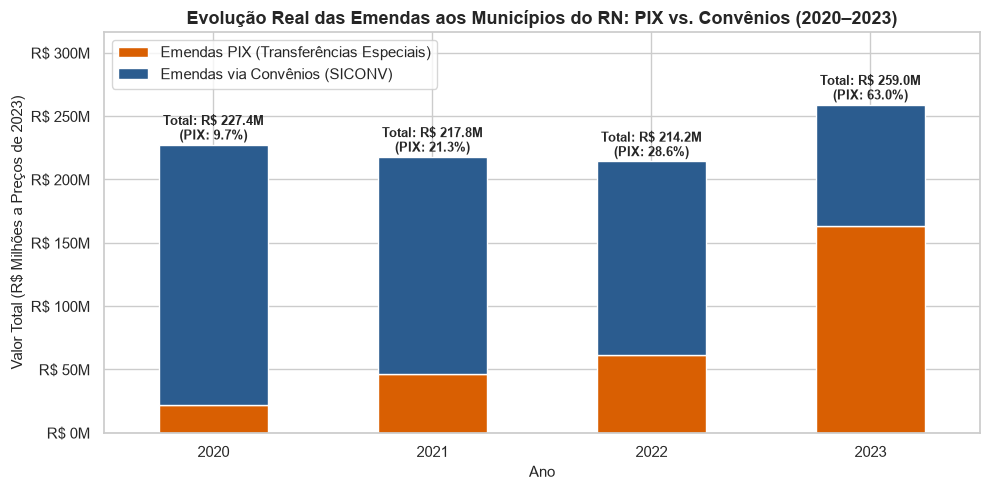

In [4]:
# Valores anuais reais por modalidade
totais_anuais_reais = df.groupby("ano").apply(
    lambda x: pd.Series({
        "Emendas PIX": (x["emendas_pix"] * x["fator_ipca"]).sum() / 1e6,
        "Emendas Convênio": (x["emendas_convenio"] * x["fator_ipca"]).sum() / 1e6
    })
)

fig, ax = plt.subplots(figsize=(10, 5))
totais_anuais_reais.plot(kind="bar", stacked=True, color=["#d95f02", "#2b5c8f"], rot=0, ax=ax)

ax.set_title("Evolução Real das Emendas aos Municípios do RN: PIX vs. Convênios (2020–2023)", fontsize=13, fontweight="bold")
ax.set_xlabel("Ano", fontsize=11)
ax.set_ylabel("Valor Total (R$ Milhões a Preços de 2023)", fontsize=11)
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:.0f}M"))

# Adicionar rótulos percentuais em cada barra
for i, ano in enumerate(totais_anuais_reais.index):
    pix = totais_anuais_reais.loc[ano, "Emendas PIX"]
    conv = totais_anuais_reais.loc[ano, "Emendas Convênio"]
    total = pix + conv
    pct_pix = (pix / total) * 100
    ax.text(i, total + 4, f"Total: R$ {total:.1f}M\n(PIX: {pct_pix:.1f}%)", ha="center", fontsize=9, fontweight="bold")

ax.legend(["Emendas PIX (Transferências Especiais)", "Emendas via Convênios (SICONV)"], loc="upper left", frameon=True)
ax.set_ylim(0, totais_anuais_reais.sum(axis=1).max() * 1.22)
plt.tight_layout()
plt.show()

> **Interpretação:**
> * Em **2020**, o instrumento dominante eram os convênios federais (90,3% do valor total).
> * Em **2023**, as **Emendas PIX saltaram para 63,0%** de todos os recursos de emendas recebidos pelos municípios potiguares.
> * A modalidade PIX dispensa celebração de convênio com ministério, análise técnica de plano de trabalho e fiscalização prévia da Caixa Econômica Federal, conferindo agilidade imediata aos prefeitos, mas reduzindo a rastreabilidade pública sobre a aplicação final do dinheiro.

## 5. Municípios Mais Beneficiados e Perfil dos Parlamentares (Quadriênio 2020–2023)

Identificamos os municípios que mais captaram emendas por habitante no acumulado dos 4 anos e os parlamentares responsáveis pelas maiores destinações.

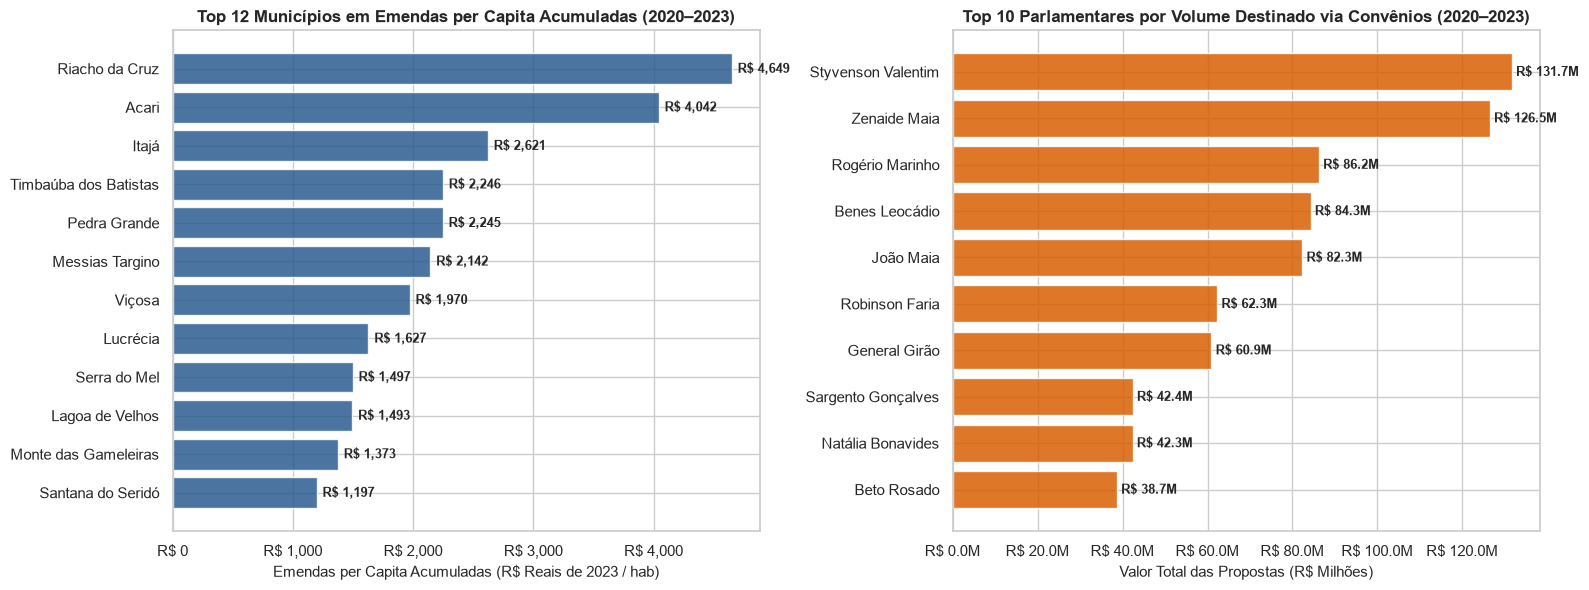

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Top 12 Municípios em Emendas per Capita Acumuladas (2020-2023)
top_mun_acum = df_acumulado.nlargest(12, "emendas_pc_acumulado").sort_values(by="emendas_pc_acumulado")

bars = axes[0].barh(top_mun_acum["municipio"], top_mun_acum["emendas_pc_acumulado"], color="#2b5c8f", alpha=0.85)
axes[0].set_title("Top 12 Municípios em Emendas per Capita Acumuladas (2020–2023)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Emendas per Capita Acumuladas (R$ Reais de 2023 / hab)", fontsize=11)
axes[0].xaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))

for bar in bars:
    w = bar.get_width()
    axes[0].text(w + 50, bar.get_y() + bar.get_height()/2, f"R$ {w:,.0f}", va="center", fontsize=9, fontweight="bold")

# Gráfico 2: Top 10 Parlamentares no Período (Convenios Federais SICONV)
caminho_conv = os.path.join("..", "dados", "emendas", "emendas_pix_rn.csv")
caminho_conv_local = os.path.join("dados", "emendas", "emendas_pix_rn.csv")
p_conv = caminho_conv if os.path.exists(caminho_conv) else caminho_conv_local

if os.path.exists(p_conv):
    df_conv_raw = pd.read_csv(p_conv)
    top_parl = df_conv_raw.groupby("nome_parlamentar_emenda_plano_acao")["valor_total_pix"].sum().nlargest(10).sort_values() / 1e6
    bars_p = axes[1].barh(top_parl.index, top_parl.values, color="#d95f02", alpha=0.85)
    axes[1].set_title("Top 10 Parlamentares por Volume Destinado via Convênios (2020–2023)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Valor Total das Propostas (R$ Milhões)", fontsize=11)
    axes[1].xaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:.1f}M"))
    for bar in bars_p:
        w = bar.get_width()
        axes[1].text(w + 1, bar.get_y() + bar.get_height()/2, f"R$ {w:.1f}M", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

> **Interpretação:**
> * No acumulado dos 4 anos, pequenas cidades tiveram aportes monumentais por habitante: **Riacho da Cruz (R$ 4.649/hab)**, **Acari (R$ 4.041/hab)**, **Itajá (R$ 2.620/hab)** e **Timbaúba dos Batistas (R$ 2.246/hab)**.
> * Em Acari e Itajá, o total acumulado em emendas ultrapassou toda a soma de repasses de ICMS e IPVA que o município arrecadou nos 4 anos inteiros.

## 6. Comparação de Cenários: Repasses Obrigatórios vs. Repasses + Emendas (2020–2023)

Comparamos visualmente os dois cenários de receita por habitante no acumulado do quadriênio para os municípios que mais receberam emendas.

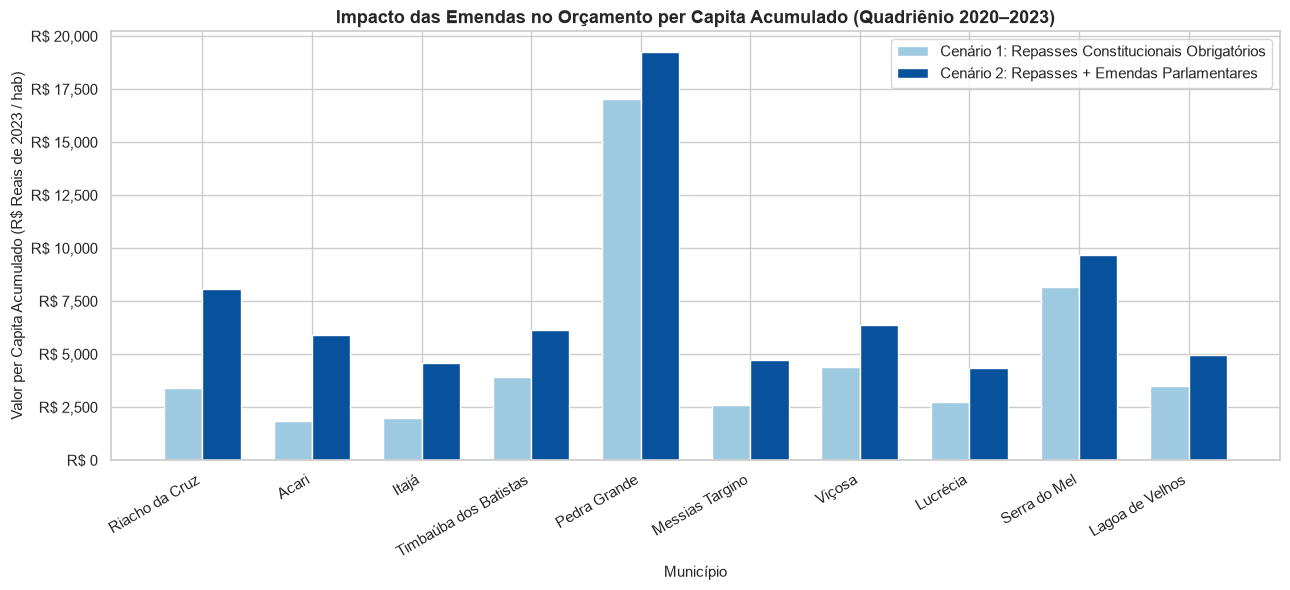

In [6]:
# Selecionar top 10 municípios em emendas per capita acumuladas
amostra_mun_acum = df_acumulado.sort_values(by="emendas_pc_acumulado", ascending=False).head(10).copy()

fig, ax = plt.subplots(figsize=(13, 6))
largura = 0.35
x = np.arange(len(amostra_mun_acum))

bar1 = ax.bar(x - largura/2, amostra_mun_acum["rep_pc_acumulado"], largura, label="Cenário 1: Repasses Constitucionais Obrigatórios", color="#9ecae1")
bar2 = ax.bar(x + largura/2, amostra_mun_acum["total_pc_acumulado"], largura, label="Cenário 2: Repasses + Emendas Parlamentares", color="#08519c")

ax.set_title("Impacto das Emendas no Orçamento per Capita Acumulado (Quadriênio 2020–2023)", fontsize=13, fontweight="bold")
ax.set_xlabel("Município", fontsize=11)
ax.set_ylabel("Valor per Capita Acumulado (R$ Reais de 2023 / hab)", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(amostra_mun_acum["municipio"], rotation=30, ha="right")
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))
ax.legend(frameon=True)

plt.tight_layout()
plt.show()

> **Interpretação:**
> Em cidades como Riacho da Cruz e Acari, as emendas parlamentares dobraram ou triplicaram a capacidade orçamentária por habitante no quadriênio, demonstrando que as transferências voluntárias federais alteram drasticamente o equilíbrio de receitas municipais fixado pela Constituição.

## 7. Experimento Natural: Comparação de "Cidades Gêmeas" no Quadriênio Completo (2020–2023)

Para testar se essa distorção foi um evento pontual de um ano ou uma realidade estrutural de todo o mandato, comparamos **pares de municípios com contingente populacional idêntico** (faixa de 5.000 a 8.000 habitantes) no interior do RN, contrastando os valores acumulados reais de 2020 a 2023.

=== TABELA COMPARATIVA DE CIDADES GÊMEAS (ACUMULADO REAL 2020-2023) ===


,par,grupo,municipio,populacao_media,pct_baixa_renda_media,emendas_total_real_acumulado,emendas_pc_acumulado,rep_pc_acumulado
0,"Par 1 (~7,3k - 7,6k hab)",Alta Alocação,Itajá,"7,292",72.2%,"R$ 19,110,718.14","R$ 2,620.78","R$ 1,961.64"
1,"Par 1 (~7,3k - 7,6k hab)",Baixa Alocação,Serra Negra do Norte,"7,597",49.8%,"R$ 3,487,070.80",R$ 459.01,"R$ 2,235.38"
2,"Par 2 (~6,4k - 8,0k hab)",Alta Alocação,Cruzeta,"8,005",59.1%,"R$ 8,063,199.42","R$ 1,007.27","R$ 1,990.16"
3,"Par 2 (~6,4k - 8,0k hab)",Baixa Alocação,Serrinha,"6,436",84.3%,"R$ 2,127,504.10",R$ 330.56,"R$ 1,695.19"
4,"Par 3 (~5,7k - 7,0k hab)",Alta Alocação,Doutor Severiano,"7,044",61.1%,"R$ 6,212,537.69",R$ 881.96,"R$ 1,571.57"
5,"Par 3 (~5,7k - 7,0k hab)",Baixa Alocação,Serra de São Bento,"5,703",70.2%,"R$ 2,698,631.77",R$ 473.20,"R$ 1,748.11"
6,"Par 4 (~5,2k - 5,4k hab)",Alta Alocação,Equador,"5,360",74.0%,"R$ 2,288,025.49",R$ 426.87,"R$ 2,983.94"
7,"Par 4 (~5,2k - 5,4k hab)",Baixa Alocação,Várzea,"5,233",64.5%,"R$ 1,795,775.52",R$ 343.16,"R$ 1,840.61"


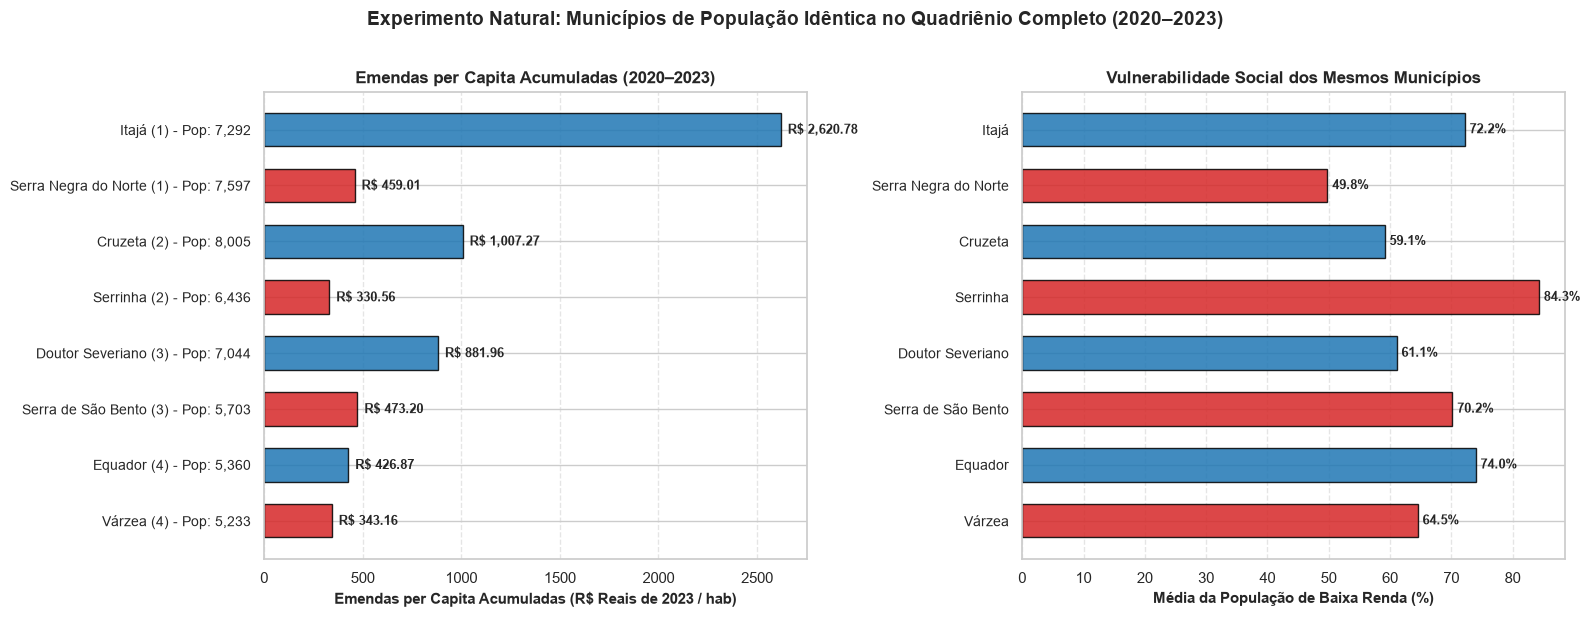

In [7]:
# Pares de contraste demográfico no acumulado 2020-2023
pares_acum = [
    {"par": "Par 1 (~7,3k - 7,6k hab)", "municipio": "Itajá", "grupo": "Alta Alocação"},
    {"par": "Par 1 (~7,3k - 7,6k hab)", "municipio": "Serra Negra do Norte", "grupo": "Baixa Alocação"},
    {"par": "Par 2 (~6,4k - 8,0k hab)", "municipio": "Cruzeta", "grupo": "Alta Alocação"},
    {"par": "Par 2 (~6,4k - 8,0k hab)", "municipio": "Serrinha", "grupo": "Baixa Alocação"},
    {"par": "Par 3 (~5,7k - 7,0k hab)", "municipio": "Doutor Severiano", "grupo": "Alta Alocação"},
    {"par": "Par 3 (~5,7k - 7,0k hab)", "municipio": "Serra de São Bento", "grupo": "Baixa Alocação"},
    {"par": "Par 4 (~5,2k - 5,4k hab)", "municipio": "Equador", "grupo": "Alta Alocação"},
    {"par": "Par 4 (~5,2k - 5,4k hab)", "municipio": "Várzea", "grupo": "Baixa Alocação"},
]

df_p_acum = pd.DataFrame(pares_acum)
df_comp_quad = pd.merge(df_p_acum, df_acumulado, on="municipio")

# Tabela consolidada de exibição
cols_tab = ["par", "grupo", "municipio", "populacao_media", "pct_baixa_renda_media", "emendas_total_real_acumulado", "emendas_pc_acumulado", "rep_pc_acumulado"]
tab_quad = df_comp_quad[cols_tab].copy()
tab_quad["pct_baixa_renda_media"] = tab_quad["pct_baixa_renda_media"].map("{:.1f}%".format)
tab_quad["populacao_media"] = tab_quad["populacao_media"].map("{:,.0f}".format)
tab_quad["emendas_total_real_acumulado"] = tab_quad["emendas_total_real_acumulado"].map("R$ {:,.2f}".format)
tab_quad["emendas_pc_acumulado"] = tab_quad["emendas_pc_acumulado"].map("R$ {:,.2f}".format)
tab_quad["rep_pc_acumulado"] = tab_quad["rep_pc_acumulado"].map("R$ {:,.2f}".format)

print("=== TABELA COMPARATIVA DE CIDADES GÊMEAS (ACUMULADO REAL 2020-2023) ===")
display(tab_quad)

# Gráficos de barras horizontais contrastando Emendas Acumuladas e Vulnerabilidade Social
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cores = ["#1f77b4" if g == "Alta Alocação" else "#d62728" for g in df_comp_quad["grupo"]]
y_pos = np.arange(len(df_comp_quad))

# 1. Emendas per capita acumuladas
bars1 = axes[0].barh(y_pos, df_comp_quad["emendas_pc_acumulado"], color=cores, alpha=0.85, edgecolor="black", height=0.6)
axes[0].set_yticks(y_pos)
y_labels = [f"{row['municipio']} ({row['par'].split()[1]}) - Pop: {float(row['populacao_media']):,.0f}" for _, row in df_comp_quad.iterrows()]
axes[0].set_yticklabels(y_labels, fontsize=10)
axes[0].invert_yaxis()
axes[0].set_xlabel("Emendas per Capita Acumuladas (R$ Reais de 2023 / hab)", fontsize=11, fontweight="bold")
axes[0].set_title("Emendas per Capita Acumuladas (2020–2023)", fontsize=12, fontweight="bold")
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

for bar in bars1:
    w = bar.get_width()
    axes[0].text(w + 35, bar.get_y() + bar.get_height()/2, f"R$ {w:,.2f}", va="center", fontsize=9, fontweight="bold")

# 2. Taxa média de Baixa Renda no CadÚnico (%)
bars2 = axes[1].barh(y_pos, df_comp_quad["pct_baixa_renda_media"], color=cores, alpha=0.85, edgecolor="black", height=0.6)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([row["municipio"] for _, row in df_comp_quad.iterrows()], fontsize=10)
axes[1].invert_yaxis()
axes[1].set_xlabel("Média da População de Baixa Renda (%)", fontsize=11, fontweight="bold")
axes[1].set_title("Vulnerabilidade Social dos Mesmos Municípios", fontsize=12, fontweight="bold")
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

for bar in bars2:
    w = bar.get_width()
    axes[1].text(w + 0.8, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=9, fontweight="bold")

plt.suptitle("Experimento Natural: Municípios de População Idêntica no Quadriênio Completo (2020–2023)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

> **Interpretação:**
> 1. **Distorção Estrutural no Mandato:** O descompasso entre cidades de mesmo porte não foi mero acaso de 2023, mas perdurou em todo o quadriênio. No Par 1, **Itajá** recebeu **R$ 2.620,78 por habitante** (R$ 19,1 milhões acumulados), enquanto **Serra Negra do Norte** recebeu apenas **R$ 459,01 por habitante** (R$ 3,4 milhões). Uma disparidade de **quase 6 vezes por morador**.
> 2. **O Paradoxo do CadÚnico Confirmado no Longo Prazo:** No Par 2, **Serrinha** possui média de **84,3% de famílias de baixa renda**, mas captou apenas R$ 330,56 por habitante em emendas. Em contraste, **Cruzeta** tem média de 59,1% de baixa renda e captou **R$ 1.007,27 por habitante** (mais de 3 vezes mais).

## 8. Síntese Executiva dos Resultados de Emendas (Quadriênio 2020–2023)

### Conclusões para o Relatório e Apresentação:
1. **Desigualdade Extrema Persistente:** Enquanto os repasses constitucionais mantêm Gini estável de 0,425, as emendas atingem Gini de até 0,690, com 0,479 no acumulado de 4 anos.
2. **Desconexão com Indicadores Sociais:** Correlação nula com pobreza no CadÚnico (r = +0,076 acumulado) e com PIB per capita (r = +0,035). As emendas não corrigem desigualdades sociais; elas seguem alinhamentos políticos.
3. **Migração Acelerada para Emendas PIX:** Saíram de 9,7% em 2020 para **63,0% em 2023**, reduzindo o controle institucional e a prestação de contas prévia.
4. **Dependência e Fragmentação:** Pequenos municípios do interior tornam-se "turbinados" por emendas, dependendo mais de deputados federais e senadores do que de sua própria base tributária ou de repasses regulares do Estado.